**Aim:** Identify cell types – UMAP visualization and clustering 

**Tools**: 
- [`scanpy`](https://scanpy.readthedocs.io/en/stable/)

<!-- ## cell typing email discussion  -->
<!-- 1) There might be a duplicate folder for the same acute female data. Please ignore the duplicate folder. And yes, I deleted the outs folder for this sample.  -->
<!-- 2) The cell counts look correct. Some are lower than others. I think for the initial analysis the MDMA male and acute male can be pooled. If necessary, you could normalize the data.  -->
<!-- 3) The tdTomato gene is annotated with Gt(ROSA)26Sor. The sequence (gene="Gt(ROSA)26Sor”) is from the Ai14 mouse line and is listed here: https://www.ncbi.nlm.nih.gov/nuccore/NR_027008  -->
<!-- Maybe it would be best to first divide the data into tdTomato+ and tdT- populations.  -->
<!-- 4) The Fos is relevant for the acute conditions, but we can focus on it later. -->
<!-- 5) I've attached the excel spreadsheet you sent with some genes labeled as potential markers.  -->
<!-- 6) I've attached a word doc with markers from papers I sent you previously. The one paper I haven't sent, I've attached here.  -->

In [1]:
import os, sys
import pickle
import numpy as np 
import pandas as pd
from glob import glob

import scanpy as sc
import scanpy.external as sce
import anndata as ad
import scvi

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import pyplot as plot
from matplotlib.backends.backend_pdf import PdfPages

sc.settings.verbosity = 1             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=300,dpi_save=300, frameon=False, figsize=(5, 5), facecolor='white')

sc.logging.print_header()

scanpy==1.9.1 anndata==0.7.6 umap==0.5.1 numpy==1.20.3 scipy==1.7.1 pandas==1.3.3 scikit-learn==1.0 statsmodels==0.13.0 python-igraph==0.9.8 pynndescent==0.5.4


In [2]:
# https://stackoverflow.com/questions/21884271/warning-about-too-many-open-figures
plt.rcParams.update({'figure.max_open_warning': 0})

plt.close('all')

In [3]:
# https://stackoverflow.com/questions/3899980/how-to-change-the-font-size-on-a-matplotlib-plot

SMALL_SIZE = 8
MEDIUM_SIZE = 10
BIGGER_SIZE = 12

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=SMALL_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title


In [4]:
from utils import *

Load preprocessed `adata`

In [5]:
results_file = 'preprocessing/adatas-merge-reps-clean.h5ad.gz'

adata = sc.read_h5ad(results_file)

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


In [6]:
adata.obs['group'] = adata.obs.cond.str.split('_').str[0]

In [7]:
adata.obs.groupby('group').size()

group
MDMA      10510
Meth       2990
Saline    10039
dtype: int64

In [8]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)

In [9]:
# clustering(adata)

In [10]:
# sc.pp.calculate_qc_metrics(adata,inplace=True)

In [11]:
# adata.layers['scaled'] = sc.pp.scale(adata, copy=True).X

In [12]:
# pdf_pages = PdfPages(f'figures/violin_mitochondrial_{cond}.pdf')
# for col in [
#     'n_genes_by_counts','total_counts',
#     'pct_counts_mt'
# ]:
#     # Create a figure instance (ie. a new page)
#     fig = plot.figure(figsize=(12, 6), dpi=300)
#     # Plot whatever you wish to plot
#     print ('\033[1m' + col)
#     ax = plt.subplot()
#     sc.pl.violin(
#         adata, col, jitter=0.4, groupby='batch', 
#         multi_panel=True, ax=ax,rotation=90
#     )
#     # Done with the page
#     pdf_pages.savefig(fig,bbox_inches='tight')
# # Write the PDF document to the disk
# pdf_pages.close()

In [13]:
# writer = pd.ExcelWriter('cell-counts.xlsx', engine='xlsxwriter')
# # Write each dataframe to a different worksheet.
# pd.concat([
#     adata.obs.groupby('cond').size(),
#     adata_flt_mt.obs.groupby('cond').size(),
#     adata_flt_dd.obs.groupby('cond').size()
# ],axis=1).rename(columns={
#     0:'raw',1:'mt filtering',2:'doublet filtering'
# }).to_excel(writer,sheet_name='conditions')
# pd.concat([
#     adata.obs.groupby('batch').size(),
#     adata_flt_mt.obs.groupby('batch').size(),
#     adata_flt_dd.obs.groupby('batch').size()
# ],axis=1).rename(columns={
#     0:'raw',1:'mt filtering',2:'doublet filtering'
# }).to_excel(writer,sheet_name='batches')
# # Close the Pandas Excel writer and output the Excel file.
# writer.save()

In [14]:
def rank_genes_to_df(adata,n=50):
    result = adata.uns['rank_genes_groups']

    groups = result['names'].dtype.names

    df = pd.DataFrame(
        {group + '_' + key: result[key][group]
        for group in groups for key in ['names', 'scores']}).head(n)
    
    return df

## Divide the data into `tdT+` and `tdT-` populations. 

In [15]:
adata

AnnData object with n_obs × n_vars = 23539 × 32285
    obs: 'batch', 'cond', 'group'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'
    layers: 'counts'

In [16]:
# tdT_gene = 'Gt(ROSA)26Sor'

In [17]:
# adata.obs['tdT'] = 'tdT-'
# adata.obs.loc[adata.obs.leiden.isin(set(adata[adata.to_df()[tdT_gene] >= 5].obs.leiden)),'tdT'] = 'tdT+'

In [ ]:
# adata[~adata.obs.leiden.isin(set(adata[adata.to_df()['Gt(ROSA)26Sor'] >= 1].obs.leiden))].obs['tdT'] = ''

In [18]:
# tdT_counts = adata.to_df()[tdT_gene]
# tdT_counts = tdT_counts[tdT_counts > 0]

# plt.figure(figsize=(4,4))
# plt.hist(tdT_counts, color='grey',bins=25)
# plt.style.use('seaborn-white')
# plt.xlabel("tdT count (normalized)")
# plt.ylabel("# of cells")
# plt.title(f'{tdT_counts.shape[0]} cells – {tdT_gene} > 0\n',fontsize=14)
# plt.savefig('figures/tdT_counts_hist.pdf',dpi = 300, bbox_inches='tight')
# plt.show()

In [19]:
# def bar_plot_tdT_clusters(adata,save=None):
#     tdT_clusters = pd.concat([
#         adata.obs['leiden'],
#         adata.to_df()[tdT_gene]
#     ],axis=1).groupby('leiden').mean()

#     plt.figure(figsize=(12,4))
#     # plt.hist(tdT_counts, color='grey',bins=25)
#     # plt.style.use('seaborn-white')
#     plt.xlabel("leiden clusters")
#     plt.ylabel("average (tdT count)")
#     # plt.title(f'{tdT_counts.shape[0]} cells – tdT>0\n')

#     plt.bar(tdT_clusters.index.tolist(),tdT_clusters[tdT_gene].tolist(),color='grey')
#     if save: 
#         plt.savefig(f'figures/tdT_counts_{save}_leiden_hist.pdf',dpi = 300, bbox_inches='tight')
#     plt.show()

In [20]:
# sc.pl.umap(
#     adata, color=['group','leiden','log1p_total_counts',tdT_gene],legend_fontsize='x-small',
#     vmin=[None,None,6,-2], vmax=[None,None,9,2], cmap='bwr', layer='scaled',
#     size=40, hspace=2,
#     save='tdT.pdf'
#     # add_outline=1
# )

# !mv figures/umaptdT.pdf figures/tdT_umap.pdf

In [21]:
# adata.shape

In [22]:
# set(adata.obs.group)

In [24]:
# Meth = adata[adata.obs.group == 'Meth']

# clustering(Meth)

# sc.pl.umap(
#     Meth, color=['batch','leiden',tdT_gene],legend_fontsize='x-small',
#     vmin=-2,vmax=2, cmap='bwr', layer='scaled',
#     size=40, hspace=2,
#     save='tdT.pdf'
#     # add_outline=1
# )

# !mv figures/umaptdT.pdf figures/tdT_umap_Meth.pdf

# bar_plot_tdT_clusters(Meth,'Meth')

In [ ]:
# adata2 = adata_flt_dd.copy()
# sc.pp.normalize_total(adata2, target_sum=1e4)
# sc.pp.log1p(adata)
# sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
# sc.pl.highly_variable_genes(adata)
# clustering(adata2)

In [ ]:
# sc.pl.umap(adata2, color='cond',save='_cond.pdf')
# sc.pl.umap(adata2, color='batch',save='_batch.pdf')
# sc.tl.rank_genes_groups(adata2, 'leiden', method='logreg')
# rank_genes_df = pd.DataFrame(adata2.uns['rank_genes_groups']['names'])

# rank_genes_df.to_excel("celltyping/rank_genes_df.xlsx",
#              sheet_name='leiden clusters')
# adata2.var_names_make_unique()

# sc.pl.violin(
#     adata2,
#     list({gene for l in rank_genes_df.head(1).values.tolist() for gene in l}), 
#     groupby='cond',save='_rank_genes_groups.png',rotation=90
# )

In [23]:
# sc.pl.rank_genes_groups(adata2, n_genes=20, sharey=False,save='.pdf')

# sc.pl.stacked_violin(
#     adata2,
#     list({gene for l in rank_genes_df.head(3).values.tolist() for gene in l}), 
#     groupby='leiden',
#     # title='mRNA Clusters',
#     save='leiden.pdf',
#     dendrogram=True
# )

# sc.pl.stacked_violin(
#     adata2,
#     list({gene for l in rank_genes_df.head(3).values.tolist() for gene in l}), 
#     groupby='cond',
#     # title='mRNA Clusters',
#     save='cond.pdf',
#     dendrogram=True
# )

## Cluster and then annotate 
<!-- neuronal/non-neuronal cells -->

In [11]:
# cell_types = {
#     "non-neuronal cells":[
#         "Endothelial","Oligodentrocyte","oligodendrocyte progenitor cells (OPCs)",
#         "Microglia","interneuron","astrocytes","neuroblast"
#     ],

#     "neuron":[
#         "neuron main markers",
#         "GABAergic",
#         "glutamatergic",
#         "D1 MSN",
#         "D2 MSN (Ppp1r1b+ medial spiny neuron)",
#         "D1H",
#         "ICj"
#     ]
# }

# marker_genes = {
#     "Endothelial": ["Cldn5","Ptprb","Ptgds"],
#     "Oligodentrocyte":["Olig1","Mog",'Opalin'],
#     "oligodendrocyte progenitor cells (OPCs)":['Pdgfra'],
#     "Microglia":["Cx3cr1",'C1qb','C1qa'],
#     "interneuron":["Resp18",'Lhx6','Zic1'],
#     "astrocytes":["Aqp4",'Slc1a3','Gja1'],
#     "neuroblast":["Top2a"],
#     "neuron main markers":['Snap25','Dck','Nrxn1',"Nfasc","Gria2","Penk",
#                            "Kctd13","Sox11","Aplp1","Syt11","Slc2a1","Slc1a2","Slc4a4","Slc6a6","Qpct"],
#     "GABAergic":["Gad1"],
#     "glutamatergic":["Slc17a7"],
#     "D1 MSN":['Tac1',"Pdyn"], # ,"Drd1a"
#     "D2 MSN (Ppp1r1b+ medial spiny neuron)":["Penk","Drd2","Adora2a"],
#     "D1H":["Nxph4","Tac2"],
#     "ICj":["Crtac1","Rreb1"],
#     "patch marker":["Sema5b"],
#     "ventral striatum marker":["Crym"],
#     "medial Shell":["Stard5","Stra6"]
# }

In [25]:
# neuron_genes = {
#     cell_type: marker_genes[cell_type] 
#     # gene 
#     for cell_type in marker_genes 
#     # for gene in marker_genes[cell_type] 
#     if cell_type in cell_types['neuron']
# }

# not_neuron_genes = {
#     cell_type: marker_genes[cell_type] 
#     # gene 
#     for cell_type in marker_genes 
#     # for gene in marker_genes[cell_type] 
#     if cell_type not in cell_types['neuron']
# }

In [ ]:
# # scale and store results in layer
# adata.layers['scaled'] = sc.pp.scale(adata, copy=True).X

# ax = sc.pl.stacked_violin(
#     adata, neuron_genes, groupby='leiden', swap_axes=False, dendrogram=True,
#     colorbar_title='mean z-score', layer='scaled', vmin=-2, vmax=2, cmap='RdBu_r'
# )

In [ ]:
# sc.pl.umap(
#     adata, 
#     color=['batch','leiden'] + list(neuron_genes),
#     legend_fontsize='x-small',
#     # vmin=-2,vmax=2, cmap='bwr', 
#     layer='scaled',
#     size=40, hspace=2,
#     # add_outline=1
# )

### Meth

In [15]:
Meth = adata[adata.obs.group == 'Meth']

In [16]:
clustering(Meth)

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


In [17]:
# scale and store results in layer
Meth.layers['scaled'] = sc.pp.scale(Meth, copy=True).X

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


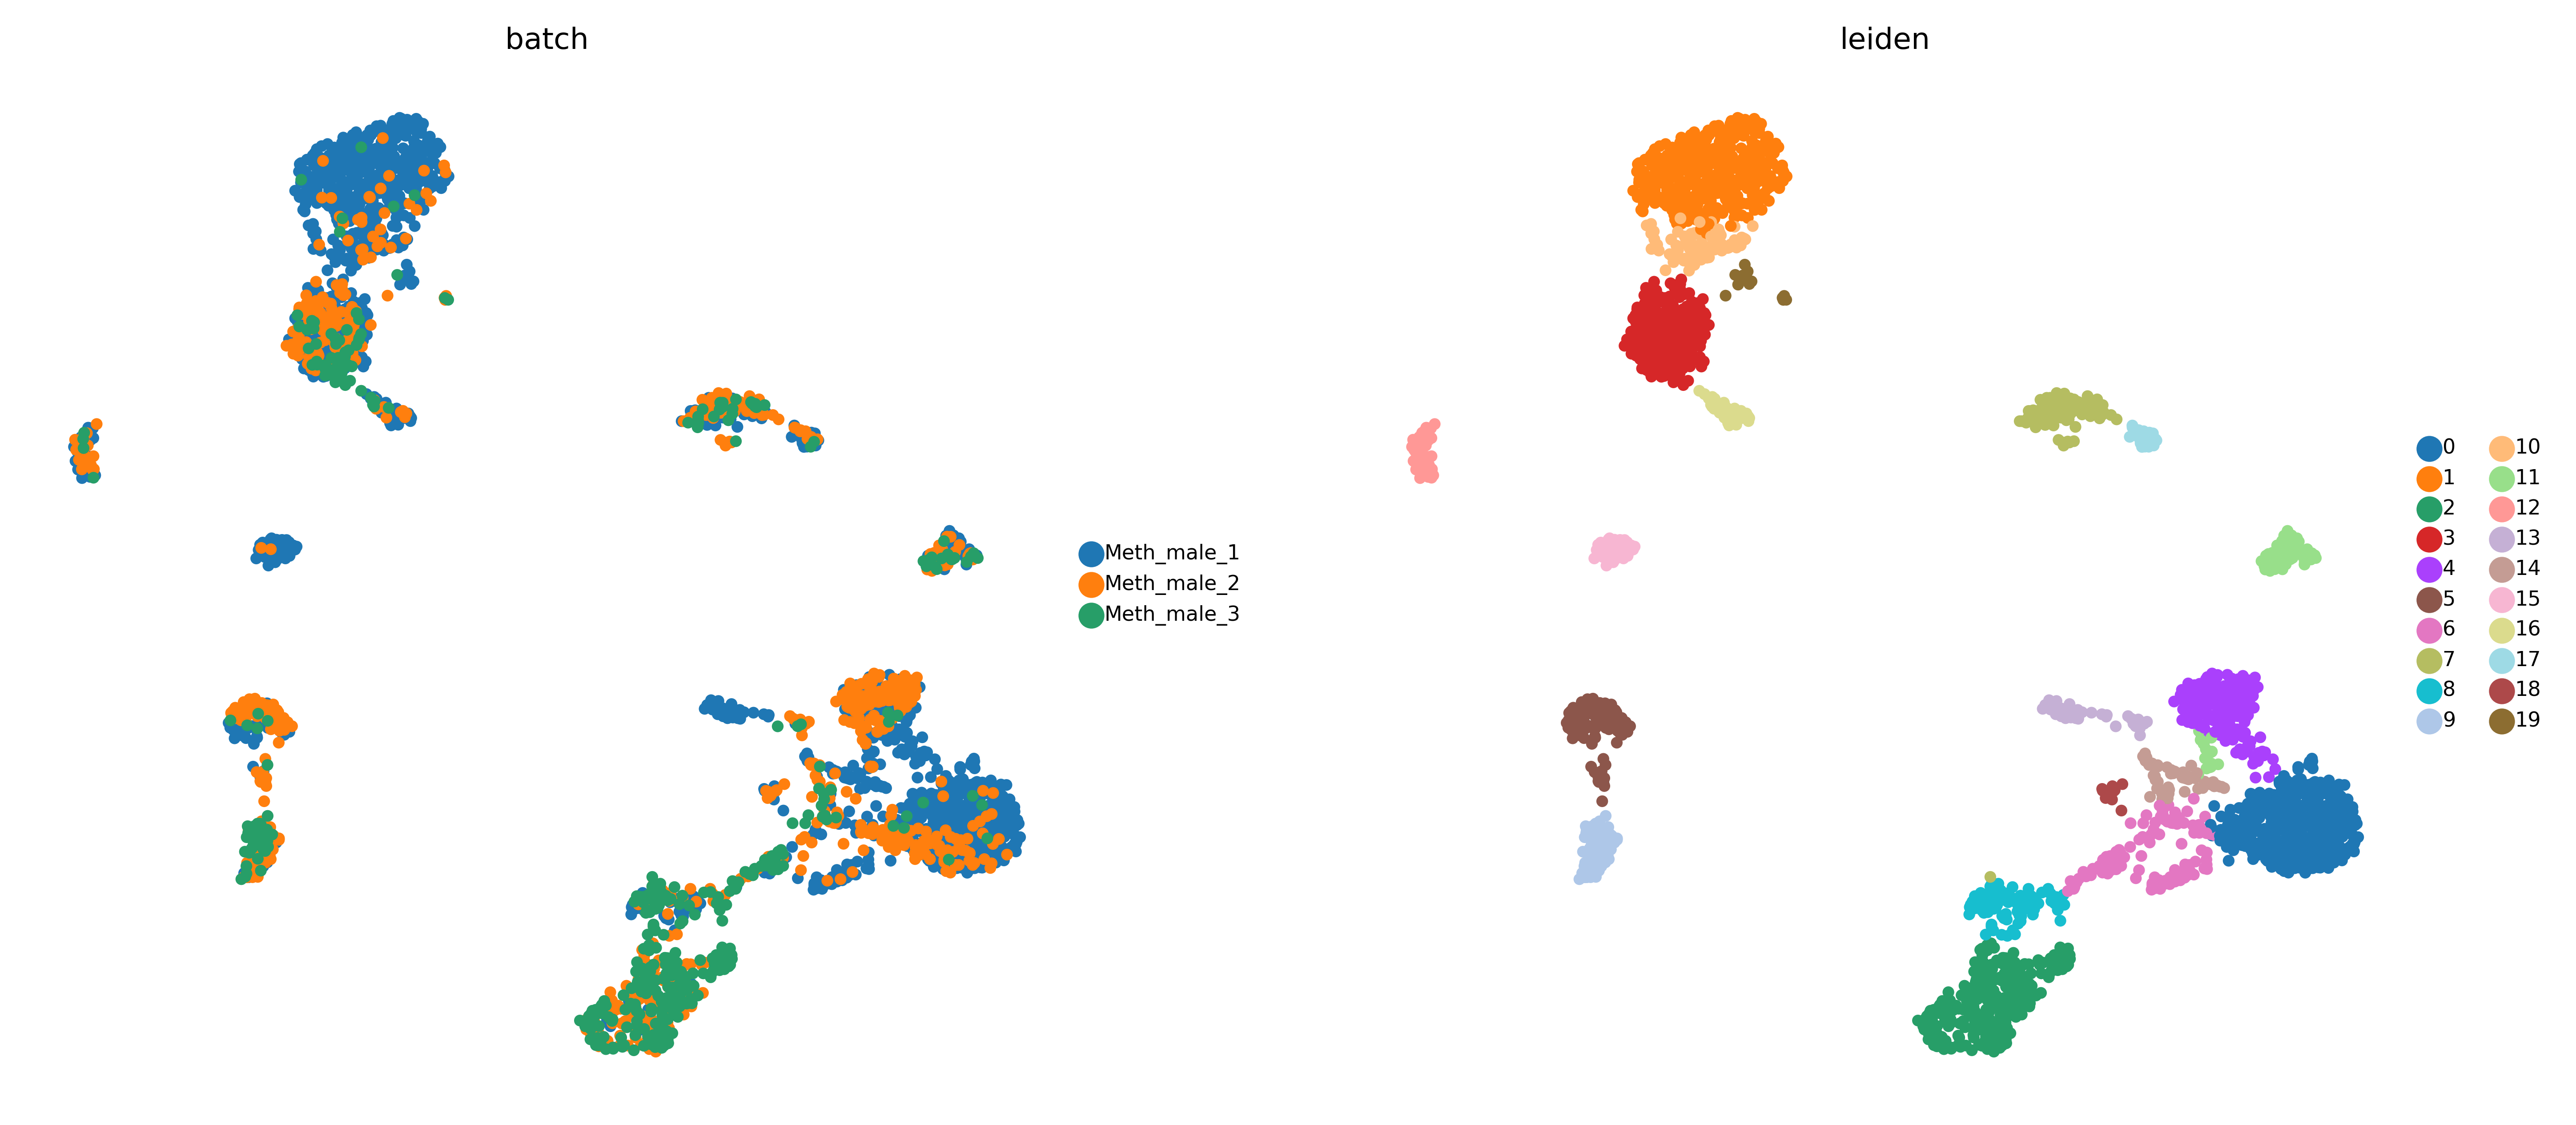

In [44]:
sc.pl.umap(
    Meth, 
    color=['batch','leiden'],# + list(neuron_genes),
    legend_fontsize='x-small',
    # vmin=-2,vmax=2, cmap='bwr', 
    layer='scaled',
    size=40, hspace=2,
    save='Meth.pdf',
    # add_outline=.1
)

!mv figures/umapMeth.pdf figures/Meth_umap.pdf

In [ ]:
ax = sc.pl.matrixplot(
    Meth, marker_genes, groupby='leiden', swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', layer='scaled', vmin=-1, vmax=1, cmap='RdBu_r',
    save='Meth.pdf'
)

!mv figures/matrixplot_Meth.pdf figures/Meth_matrixplot.pdf

In [ ]:
ax = sc.pl.matrixplot(
    Meth, neuron_genes, groupby='leiden', swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', layer='scaled', vmin=-1, vmax=1, cmap='RdBu_r',
    save='Meth_neuron.pdf'
)

!mv figures/matrixplot_Meth_neuron.pdf figures/Meth_neuron_matrixplot.pdf

In [ ]:
ax = sc.pl.matrixplot(
    Meth, not_neuron_genes, groupby='leiden', swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', layer='scaled', vmin=-1, vmax=1, cmap='RdBu_r',
    save='Meth_not_neuron.pdf'
)

!mv figures/matrixplot_Meth_not_neuron.pdf figures/Meth_not_neuron_matrixplot.pdf

In [ ]:
sc.tl.rank_genes_groups(Meth, 'leiden', method='logreg')

In [ ]:
rank_genes_to_df(Meth).to_csv('celltyping/Meth_rank_genes.csv')

In [ ]:
Meth.write_h5ad("celltyping/Meth.h5ad.gz",compression=True)

### MDMA

In [24]:
MDMA = adata[adata.obs.group == 'MDMA']

In [25]:
clustering(MDMA)

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


In [26]:
# scale and store results in layer
MDMA.layers['scaled'] = sc.pp.scale(MDMA, copy=True).X

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


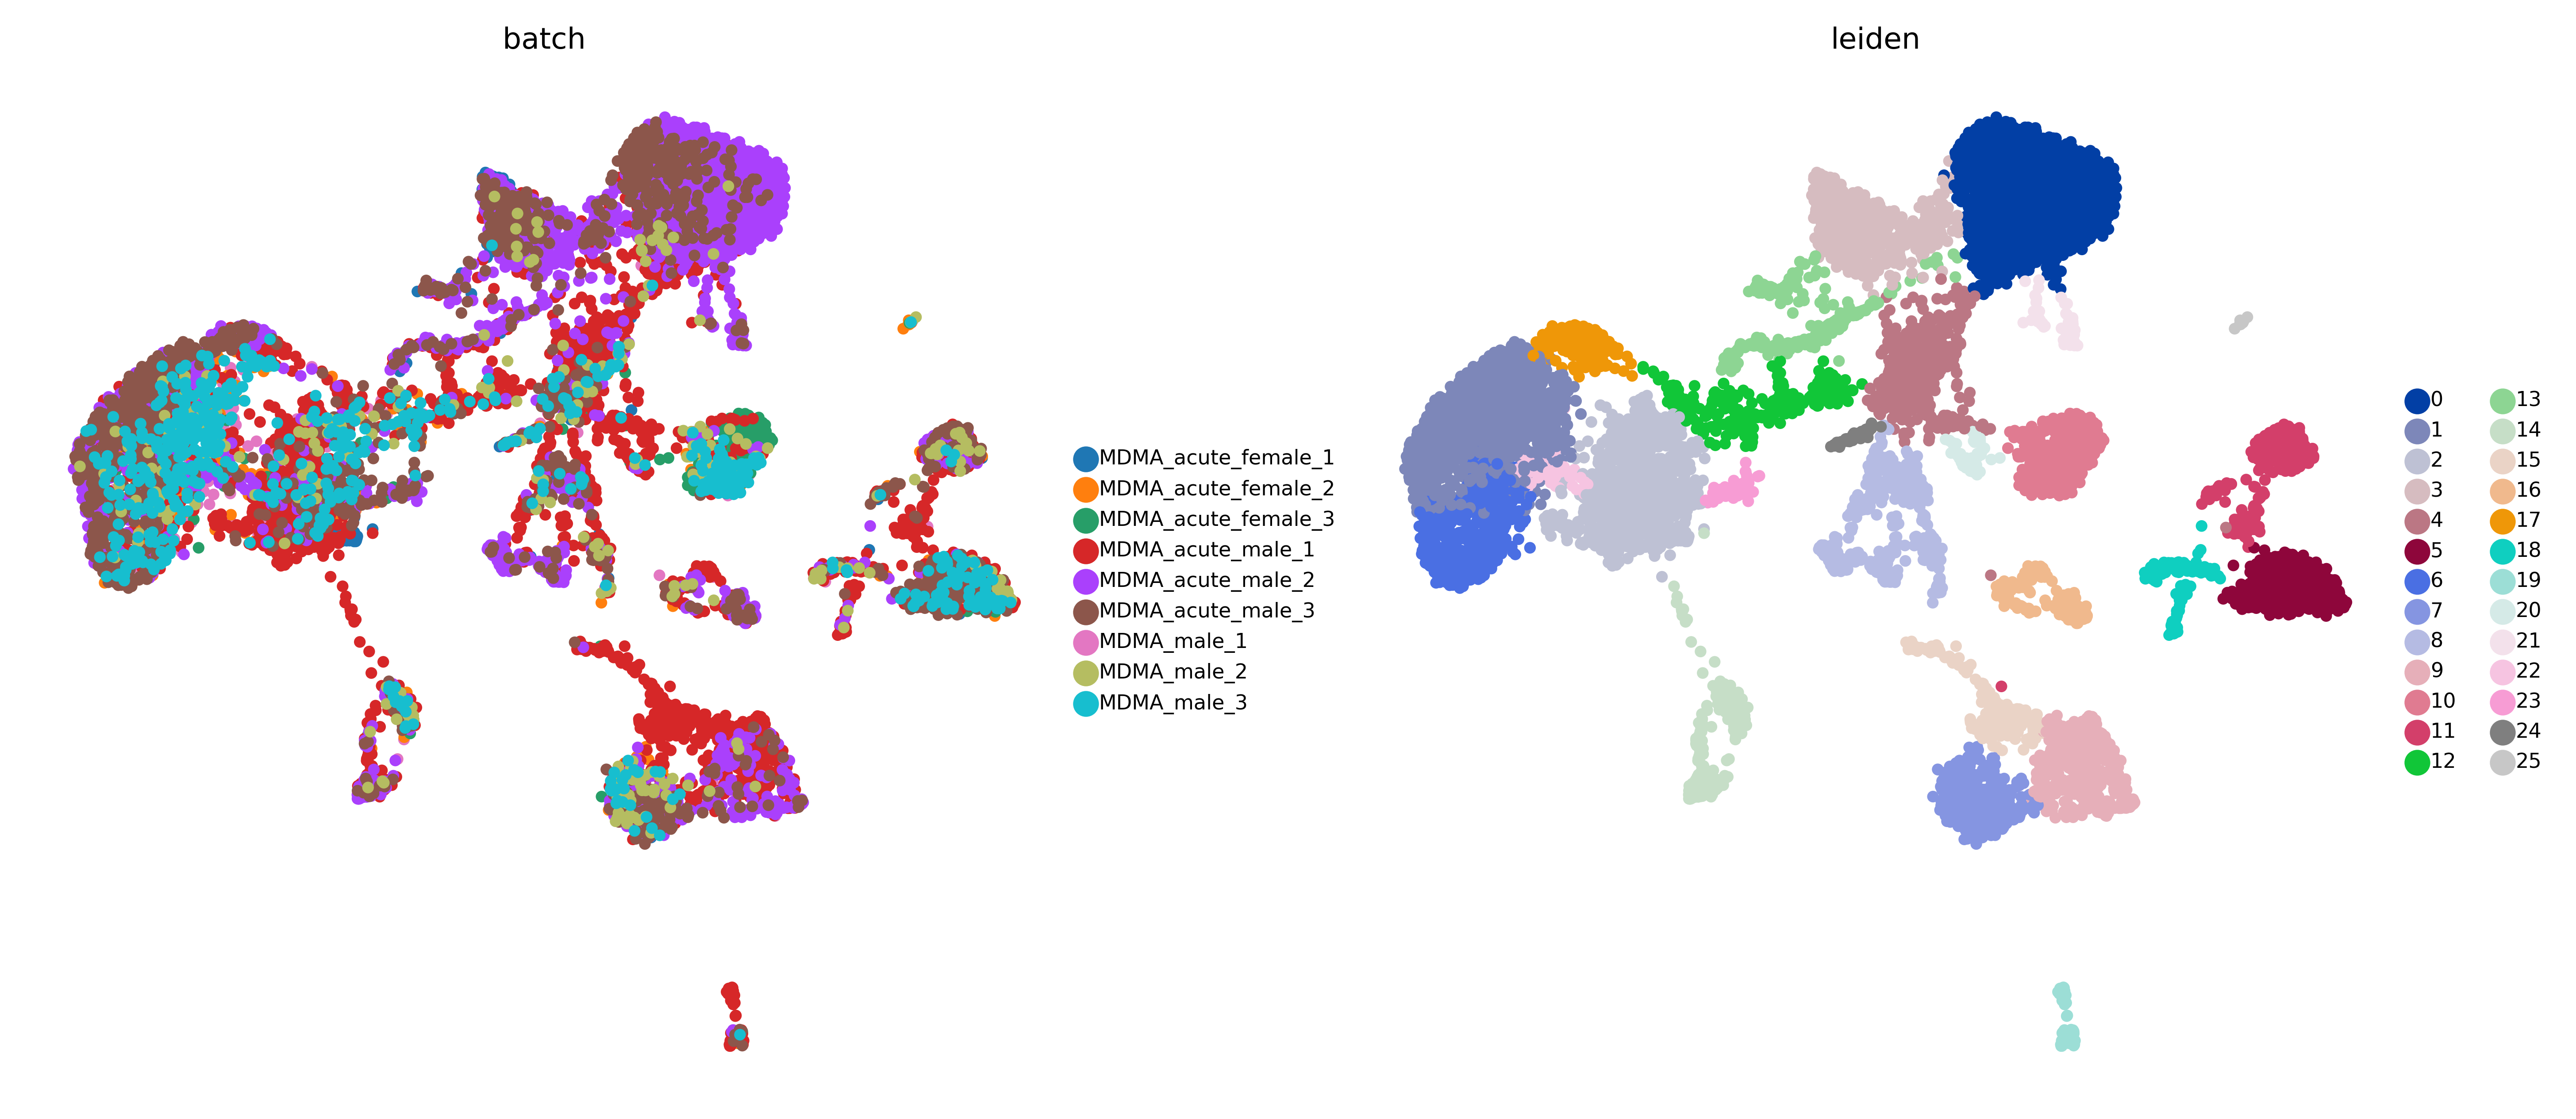

In [50]:
sc.pl.umap(
    MDMA, 
    color=['batch','leiden'],# + list(neuron_genes),
    legend_fontsize='x-small',
    size=40, hspace=2,
    save='MDMA.pdf'
    # add_outline=1
)

!mv figures/umapMDMA.pdf figures/MDMA_umap.pdf

In [ ]:
ax = sc.pl.matrixplot(
    MDMA, marker_genes, groupby='leiden', swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', layer='scaled', vmin=-1, vmax=1, cmap='RdBu_r',
    save='MDMA.pdf'
)

!mv figures/matrixplot_MDMA.pdf figures/MDMA_matrixplot.pdf

In [ ]:
ax = sc.pl.matrixplot(
    MDMA, neuron_genes, groupby='leiden', swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', layer='scaled', vmin=-1, vmax=1, cmap='RdBu_r',
    save='MDMA_neuron.pdf'
)

!mv figures/matrixplot_MDMA_neuron.pdf figures/MDMA_neuron_matrixplot.pdf

In [ ]:
ax = sc.pl.matrixplot(
    MDMA, not_neuron_genes, groupby='leiden', swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', layer='scaled', vmin=-1, vmax=1, cmap='RdBu_r',
    save='MDMA_not_neuron.pdf'
)

!mv figures/matrixplot_MDMA_not_neuron.pdf figures/MDMA_not_neuron_matrixplot.pdf

In [ ]:
sc.tl.rank_genes_groups(MDMA, 'leiden', method='logreg')

In [ ]:
rank_genes_to_df(MDMA).to_csv('celltyping/MDMA_rank_genes.csv')

In [84]:
MDMA.write_h5ad("celltyping/MDMA.h5ad.gz",compression=True)

### Saline

In [62]:
Saline = adata[adata.obs.group == 'Saline']

In [63]:
clustering(Saline)

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


In [64]:
# scale and store results in layer
Saline.layers['scaled'] = sc.pp.scale(Saline, copy=True).X

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


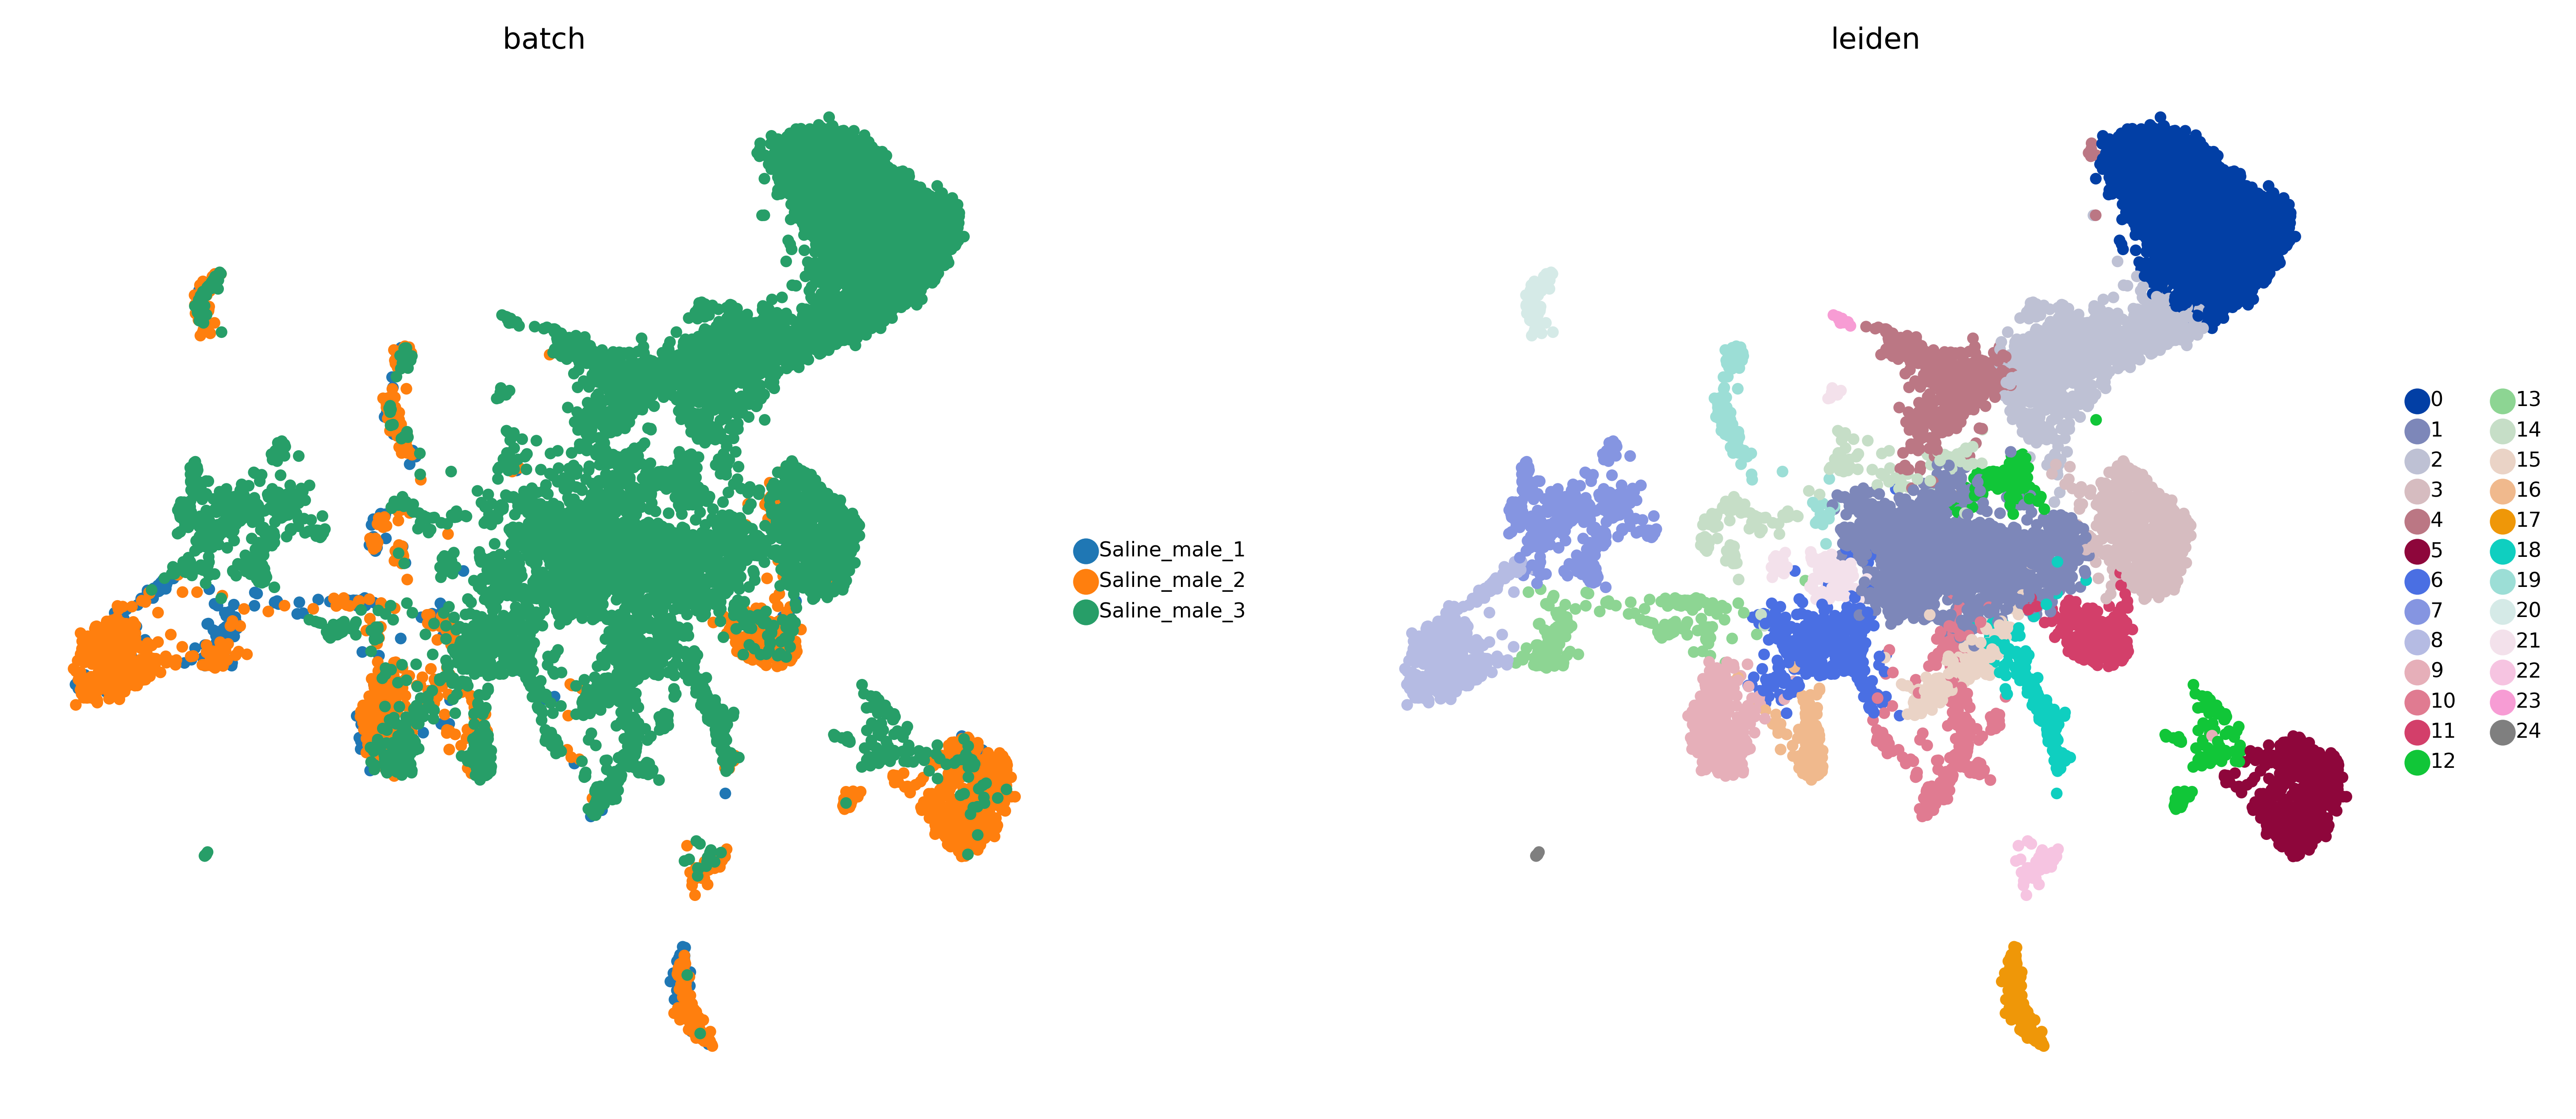

In [87]:
sc.pl.umap(
    Saline, 
    color=['batch','leiden'],# + list(neuron_genes),
    legend_fontsize='x-small',
    size=40, hspace=2,
    save='Saline.pdf'
    # add_outline=1
)

!mv figures/umapSaline.pdf figures/Saline_umap.pdf

In [ ]:
ax = sc.pl.matrixplot(
    Saline, marker_genes, groupby='leiden', swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', layer='scaled', vmin=-1, vmax=1, cmap='RdBu_r',
    save='Saline.pdf'
)

!mv figures/matrixplot_Saline.pdf figures/Saline_matrixplot.pdf

In [ ]:
ax = sc.pl.matrixplot(
    Saline, neuron_genes, groupby='leiden', swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', layer='scaled', vmin=-1, vmax=1, cmap='RdBu_r',
    save='Saline_neuron.pdf'
)

!mv figures/matrixplot_Saline_neuron.pdf figures/Saline_neuron_matrixplot.pdf

In [ ]:
ax = sc.pl.matrixplot(
    Saline, not_neuron_genes, groupby='leiden', swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', layer='scaled', vmin=-1, vmax=1, cmap='RdBu_r',
    save='Saline_not_neuron.pdf'
)

!mv figures/matrixplot_Saline_not_neuron.pdf figures/Saline_not_neuron_matrixplot.pdf

In [73]:
sc.tl.rank_genes_groups(Saline, 'leiden', method='logreg')

/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:814: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [74]:
rank_genes_to_df(Saline).to_csv('celltyping/Saline_rank_genes.csv')

In [81]:
Saline.write_h5ad("celltyping/Saline.h5ad.gz",compression=True)

In [86]:
ls -lh celltyping/

total 1.1G
-rw-rw-r--. 1 aarab aarab 342M May 22 13:35 MDMA.h5ad.gz
-rw-rw-r--. 1 aarab aarab  23K May 22 13:28 MDMA_rank_genes.csv
-rw-rw-r--. 1 aarab aarab 111M May 22 13:35 Meth.h5ad.gz
-rw-rw-r--. 1 aarab aarab  18K May 22 13:28 Meth_rank_genes.csv
-rw-rw-r--. 1 aarab aarab 325M May 22 13:34 Saline.h5ad.gz
-rw-rw-r--. 1 aarab aarab  22K May 22 13:30 Saline_rank_genes.csv


In [76]:
!date

Sun May 22 13:31:15 PDT 2022
